In [3]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set_theme(style="whitegrid")

# Display all columns when needed
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv("Train.csv")

# Display the first five records
display(df.head())

# Check the number of rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Check column names and data types
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

# Generate descriptive statistics
display(df.describe())

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


Number of rows: 10999
Number of columns: 12

Column names:
['ID', 'Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms', 'Reached.on.Time_Y.N']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   10999 non-null  int64 
 1   Warehouse_block      10999 non-null  object
 2   Mode_of_Shipment     10999 non-null  object
 3   Customer_care_calls  10999 non-null  int64 
 4   Customer_rating      10999 non-null  int64 
 5   Cost_of_the_Product  10999 non-null  int64 
 6   Prior_purchases      10999 non-null  int64 
 7   Product_importance   10999 non-null  object
 8   Gender               10999 non-null  object
 9   Discount_offered     10999 non-null  int64 


,ID,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
count,10999.00000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000
mean,5500.00000,4.054459,2.990545,210.196836,3.567597,13.373216,3634.016729,0.596691
std,3175.28214,1.141490,1.413603,48.063272,1.522860,16.205527,1635.377251,0.490584
min,1.00000,2.000000,1.000000,96.000000,2.000000,1.000000,1001.000000,0.000000
25%,2750.50000,3.000000,2.000000,169.000000,3.000000,4.000000,1839.500000,0.000000
50%,5500.00000,4.000000,3.000000,214.000000,3.000000,7.000000,4149.000000,1.000000
75%,8249.50000,5.000000,4.000000,251.000000,4.000000,10.000000,5050.000000,1.000000
max,10999.00000,7.000000,5.000000,310.000000,10.000000,65.000000,7846.000000,1.000000


In [5]:
# Count missing values in each column
print(df.isnull().sum())

# Calculate the percentage of missing values
missing_percent = (df.isnull().sum() / len(df)) * 100
print("\nMissing values percentage:")
print(missing_percent)


ID                     0
Warehouse_block        0
Mode_of_Shipment       0
Customer_care_calls    0
Customer_rating        0
Cost_of_the_Product    0
Prior_purchases        0
Product_importance     0
Gender                 0
Discount_offered       0
Weight_in_gms          0
Reached.on.Time_Y.N    0
dtype: int64

Missing values percentage:
ID                     0.0
Warehouse_block        0.0
Mode_of_Shipment       0.0
Customer_care_calls    0.0
Customer_rating        0.0
Cost_of_the_Product    0.0
Prior_purchases        0.0
Product_importance     0.0
Gender                 0.0
Discount_offered       0.0
Weight_in_gms          0.0
Reached.on.Time_Y.N    0.0
dtype: float64


In [6]:
# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows if any exist
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Duplicate rows: 0
Dataset shape after removing duplicates: (10999, 12)


In [7]:
# Check unique categorical values
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}:")
    print(df[col].unique())

# Check the delivery outcome values
print("\nDelivery outcome values:")
print(df["Reached.on.Time_Y.N"].value_counts())


Warehouse_block:
['D' 'F' 'A' 'B' 'C']

Mode_of_Shipment:
['Flight' 'Ship' 'Road']

Product_importance:
['low' 'medium' 'high']

Gender:
['F' 'M']

Delivery outcome values:
Reached.on.Time_Y.N
1    6563
0    4436
Name: count, dtype: int64


In [9]:
# Convert the delivery outcome into readable categories
df["Delivery_Status"] = df["Late_Delivery"].map({
    0: "On Time",
    1: "Late"
})

# Convert weight from grams to kilograms
df["Weight_kg"] = df["Weight_g"] / 1000

# Group product cost into three descriptive categories
df["Cost_Category"] = pd.cut(
    df["Product_Cost"],
    bins=[-float("inf"), 100, 200, float("inf")],
    labels=["Low Cost", "Medium Cost", "High Cost"]
)

display(df[[
    "Product_Cost", "Cost_Category",
    "Weight_g", "Weight_kg",
    "Late_Delivery", "Delivery_Status"
]].head())

KeyError: 'Late_Delivery'

In [10]:
print("Final dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


Final dataset shape: (10999, 12)
Missing values: 0
Duplicate rows: 0


In [11]:
display(df.describe())

# Average, minimum, and maximum product cost
print("Average product cost:", df["Product_Cost"].mean())
print("Minimum product cost:", df["Product_Cost"].min())
print("Maximum product cost:", df["Product_Cost"].max())

# Average weight
print("Average product weight (grams):", df["Weight_g"].mean())

# Overall late-delivery percentage
print(
    "Late delivery percentage:",
    round(df["Late_Delivery"].mean() * 100, 2), "%"
)


,ID,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
count,10999.00000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000
mean,5500.00000,4.054459,2.990545,210.196836,3.567597,13.373216,3634.016729,0.596691
std,3175.28214,1.141490,1.413603,48.063272,1.522860,16.205527,1635.377251,0.490584
min,1.00000,2.000000,1.000000,96.000000,2.000000,1.000000,1001.000000,0.000000
25%,2750.50000,3.000000,2.000000,169.000000,3.000000,4.000000,1839.500000,0.000000
50%,5500.00000,4.000000,3.000000,214.000000,3.000000,7.000000,4149.000000,1.000000
75%,8249.50000,5.000000,4.000000,251.000000,4.000000,10.000000,5050.000000,1.000000
max,10999.00000,7.000000,5.000000,310.000000,10.000000,65.000000,7846.000000,1.000000


KeyError: 'Product_Cost'

In [13]:
print("Shipment mode distribution:")
display(df["Mode_of_Shipment"].value_counts())

print("\nProduct importance distribution:")
display(df["Product_importance"].value_counts())

print("\nWarehouse distribution:")
display(df["Warehouse_block"].value_counts())

# Create Delivery_Status if it does not exist
if "Delivery_Status" not in df.columns:
    df["Delivery_Status"] = df["Reached.on.Time_Y.N"].map({
        0: "On Time",
        1: "Late"
    })

print("\nDelivery status distribution:")
display(df["Delivery_Status"].value_counts())


Shipment mode distribution:


Mode_of_Shipment
Ship      7462
Flight    1777
Road      1760
Name: count, dtype: int64


Product importance distribution:


Product_importance
low       5297
medium    4754
high       948
Name: count, dtype: int64


Warehouse distribution:


Warehouse_block
F    3666
D    1834
A    1833
B    1833
C    1833
Name: count, dtype: int64


Delivery status distribution:


Delivery_Status
Late       6563
On Time    4436
Name: count, dtype: int64

In [15]:
df.columns = df.columns.str.strip()

# Detect the correct column names
shipment_col = (
    "Shipment_Mode"
    if "Shipment_Mode" in df.columns
    else "Mode_of_Shipment"
)

delivery_col = (
    "Late_Delivery"
    if "Late_Delivery" in df.columns
    else "Reached.on.Time_Y.N"
)

weight_col = (
    "Weight_g"
    if "Weight_g" in df.columns
    else "Weight_in_gms"
)

# Group and calculate statistics
shipment_analysis = (
    df.groupby(shipment_col)
      .agg(
          Total_Orders=(delivery_col, "size"),
          Late_Delivery_Rate=(delivery_col, "mean"),
          Average_Weight=(weight_col, "mean")
      )
)

# Convert rate to percentage
shipment_analysis["Late_Delivery_Rate"] *= 100

# Display the result
display(shipment_analysis.round(2))

,Total_Orders,Late_Delivery_Rate,Average_Weight
Mode_of_Shipment,,,
Flight,1777,60.16,3629.38
Road,1760,58.81,3649.55
Ship,7462,59.76,3631.46


In [17]:
df.columns = df.columns.str.strip()

# Automatically detect the column names
shipment_col = (
    "Shipment_Mode" if "Shipment_Mode" in df.columns
    else "Mode_of_Shipment"
)

importance_col = (
    "Product_Importance" if "Product_Importance" in df.columns
    else "Product_importance"
)

delivery_col = (
    "Late_Delivery" if "Late_Delivery" in df.columns
    else "Reached.on.Time_Y.N"
)

# Create pivot table
pivot_table = pd.pivot_table(
    df,
    index=shipment_col,
    columns=importance_col,
    values=delivery_col,
    aggfunc="mean",
    observed=False
) * 100

# Display the results
print("Late-delivery outcome (%) by shipment mode and product importance:")
display(pivot_table.round(2))


Late-delivery outcome (%) by shipment mode and product importance:


Product_importance,high,low,medium
Mode_of_Shipment,,,
Flight,58.28,59.90,60.82
Road,65.19,58.81,57.45
Ship,66.67,59.24,58.99


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

# Display correlation matrix
display(correlation_matrix.round(2))


,ID,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
ID,1.00,0.19,-0.01,0.20,0.15,-0.60,0.28,-0.41
Customer_care_calls,0.19,1.00,0.01,0.32,0.18,-0.13,-0.28,-0.07
Customer_rating,-0.01,0.01,1.00,0.01,0.01,-0.00,-0.00,0.01
Cost_of_the_Product,0.20,0.32,0.01,1.00,0.12,-0.14,-0.13,-0.07
Prior_purchases,0.15,0.18,0.01,0.12,1.00,-0.08,-0.17,-0.06
Discount_offered,-0.60,-0.13,-0.00,-0.14,-0.08,1.00,-0.38,0.40
Weight_in_gms,0.28,-0.28,-0.00,-0.13,-0.17,-0.38,1.00,-0.27
Reached.on.Time_Y.N,-0.41,-0.07,0.01,-0.07,-0.06,0.40,-0.27,1.00


Shipment mode distribution


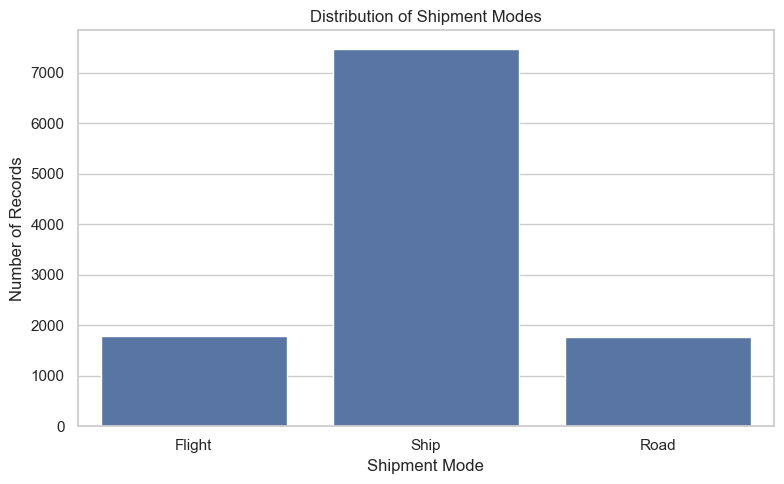

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Find the correct shipment column
if "Shipment_Mode" in df.columns:
    shipment_col = "Shipment_Mode"
elif "Mode_of_Shipment" in df.columns:
    shipment_col = "Mode_of_Shipment"
else:
    raise ValueError(
        "Shipment column not found. Available columns: "
        + str(df.columns.tolist())
    )

# Create the chart
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=shipment_col)

plt.title("Distribution of Shipment Modes")
plt.xlabel("Shipment Mode")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


Product cost distribution

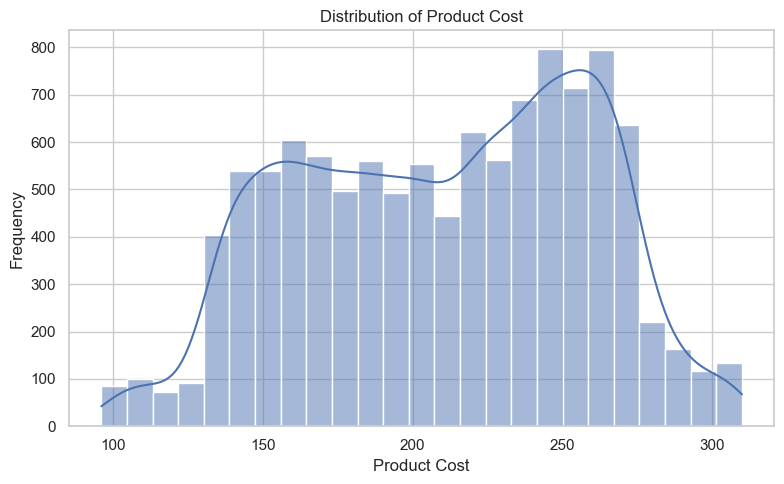

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Automatically identify the correct column
if "Product_Cost" in df.columns:
    cost_col = "Product_Cost"
elif "Cost_of_the_Product" in df.columns:
    cost_col = "Cost_of_the_Product"
else:
    raise ValueError("Product cost column not found. Check df.columns.tolist().")

# Generate histogram
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x=cost_col, bins=25, kde=True)

plt.title("Distribution of Product Cost")
plt.xlabel("Product Cost")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


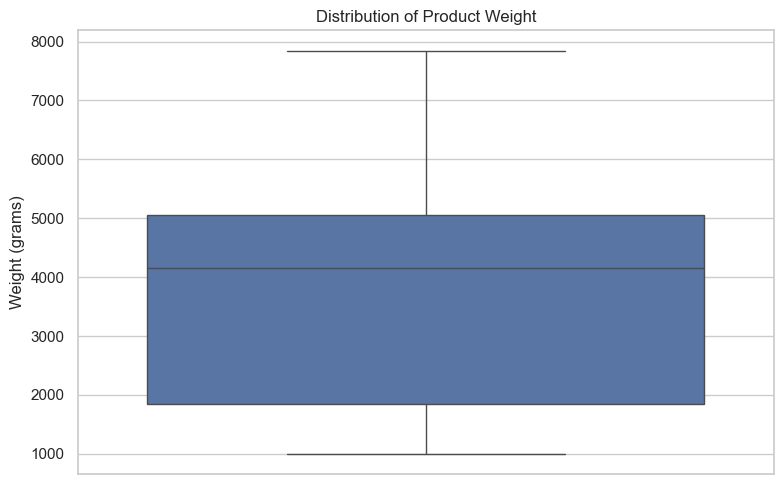

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Identify the correct weight column
if "Weight_g" in df.columns:
    weight_col = "Weight_g"
elif "Weight_in_gms" in df.columns:
    weight_col = "Weight_in_gms"
else:
    print("Available columns:", df.columns.tolist())
    raise ValueError("Weight column not found.")

# Convert weight to numeric
df[weight_col] = pd.to_numeric(df[weight_col], errors="coerce")

# Remove missing values for the chart
weight_data = df[weight_col].dropna()

# Create box plot
plt.figure(figsize=(8, 5))
sns.boxplot(y=weight_data)

plt.title("Distribution of Product Weight")
plt.ylabel("Weight (grams)")
plt.tight_layout()
plt.show()


Late deliveries by shipment mode

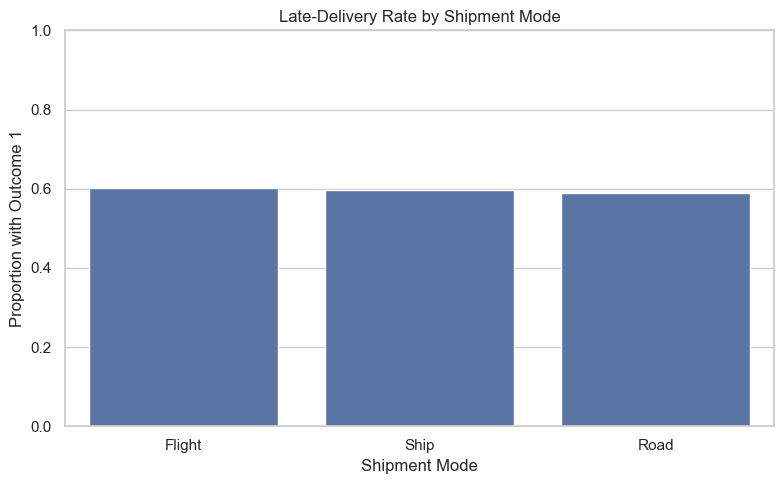

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Clean column names
df.columns = df.columns.str.strip()

# Identify the correct shipment column
shipment_col = next(
    (c for c in ["Shipment_Mode", "Mode_of_Shipment"]
     if c in df.columns),
    None
)

# Identify the correct delivery outcome column
delivery_col = next(
    (c for c in ["Late_Delivery", "Reached.on.Time_Y.N"]
     if c in df.columns),
    None
)

# Check that both columns exist
if shipment_col is None or delivery_col is None:
    print("Available columns:", df.columns.tolist())
    raise ValueError("Shipment or delivery column not found.")

# Convert delivery outcome to numeric
df[delivery_col] = pd.to_numeric(
    df[delivery_col], errors="coerce"
)

# Remove rows with missing values in these columns
plot_df = df[[shipment_col, delivery_col]].dropna()

# Create bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    data=plot_df,
    x=shipment_col,
    y=delivery_col,
    errorbar=None
)

plt.title("Late-Delivery Rate by Shipment Mode")
plt.xlabel("Shipment Mode")
plt.ylabel("Proportion with Outcome 1")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


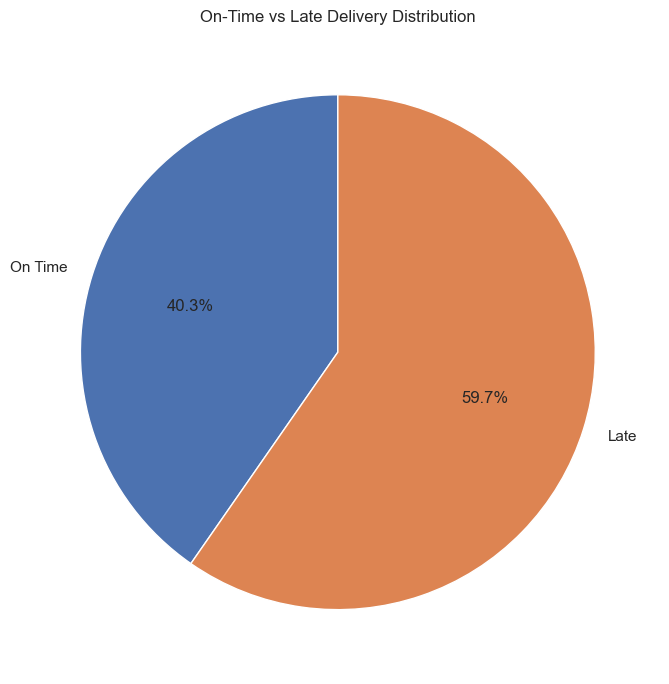

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# Clean column names
df.columns = df.columns.str.strip()

# Detect the delivery outcome column
if "Late_Delivery" in df.columns:
    delivery_col = "Late_Delivery"
elif "Reached.on.Time_Y.N" in df.columns:
    delivery_col = "Reached.on.Time_Y.N"
else:
    print("Available columns:", df.columns.tolist())
    raise ValueError("Delivery outcome column not found.")

# Convert outcome values to numeric
df[delivery_col] = pd.to_numeric(
    df[delivery_col], errors="coerce"
)

# Remove missing values
delivery_data = df[delivery_col].dropna()

# Create readable status labels
status_counts = delivery_data.map({
    0: "On Time",
    1: "Late"
}).value_counts().reindex(
    ["On Time", "Late"], fill_value=0
)

# Plot pie chart
plt.figure(figsize=(7, 7))
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("On-Time vs Late Delivery Distribution")
plt.tight_layout()
plt.show()


Conclusion

This project analyses an e-commerce shipment dataset using Python. The analysis includes data loading, preprocessing, descriptive statistics, exploratory data analysis, groupby operations, pivot tables, correlation analysis, and visualizations.

The dataset contains 10,999 records and 12 original columns. Initial quality checks found no missing values or duplicate rows. Additional derived columns were created to support the analysis.

The exploratory analysis examines shipment methods, product costs, product weights, customer ratings, discounts, product importance, and delivery outcomes. The numerical analysis indicates associations between the delivery outcome, discount offered, and product weight.

The findings can help identify areas for further investigation in shipment operations. Potential next steps include examining the reasons for delivery delays, comparing delivery performance across relevant groups, and investigating whether discount levels and product characteristics are associated with delivery outcomes.

The analysis is descriptive and does not establish causal relationships. Further investigation would be required before making operational changes